In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

print("Qiskit Fall Fest 2026")
print("Challenge 4: Quantum Correlation Switch")
print("Simulator initialized successfully!")

Qiskit Fall Fest 2026
Challenge 4: Quantum Correlation Switch
Simulator initialized successfully!


In [2]:
predictions = {
    "Part A - Correlated": {
        "00": 50,
        "01": 0,
        "10": 0,
        "11": 50
    },
    "Part B - Opposite": {
        "00": 0,
        "01": 50,
        "10": 50,
        "11": 0
    }
}

print("PREDICTIONS BEFORE EXECUTION")
print("=" * 60)

for name, prediction in predictions.items():
    print(f"\n{name}")
    for state, percentage in prediction.items():
        print(f"{state}: {percentage}%")

PREDICTIONS BEFORE EXECUTION

Part A - Correlated
00: 50%
01: 0%
10: 0%
11: 50%

Part B - Opposite
00: 0%
01: 50%
10: 50%
11: 0%


PART A - CORRELATED OUTCOMES


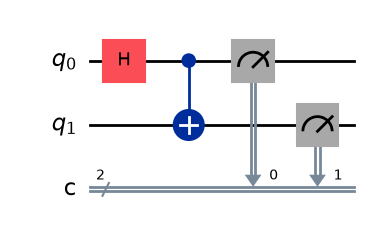

In [3]:
circuit_a = QuantumCircuit(2, 2)

circuit_a.h(0)
circuit_a.cx(0, 1)

circuit_a.measure([0, 1], [0, 1])

print("PART A - CORRELATED OUTCOMES")
display(circuit_a.draw("mpl"))

PART B - OPPOSITE OUTCOMES


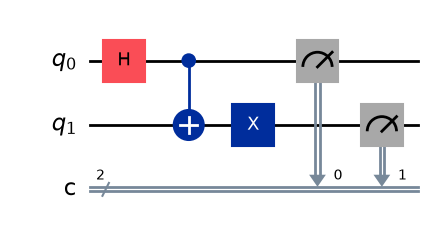

In [4]:
circuit_b = QuantumCircuit(2, 2)

circuit_b.h(0)
circuit_b.cx(0, 1)

# Correlation switch
circuit_b.x(1)

circuit_b.measure([0, 1], [0, 1])

print("PART B - OPPOSITE OUTCOMES")
display(circuit_b.draw("mpl"))

In [5]:
circuits = {
    "Part A - Correlated": circuit_a,
    "Part B - Opposite": circuit_b
}

results = {}

for name, circuit in circuits.items():

    compiled = transpile(circuit, simulator)

    job = simulator.run(compiled, shots=shots)

    counts = job.result().get_counts()

    results[name] = counts

    print(f"{name}: {counts}")

print("\nBoth circuits executed successfully!")

Part A - Correlated: {'11': 56, '00': 44}
Part B - Opposite: {'01': 55, '10': 45}

Both circuits executed successfully!


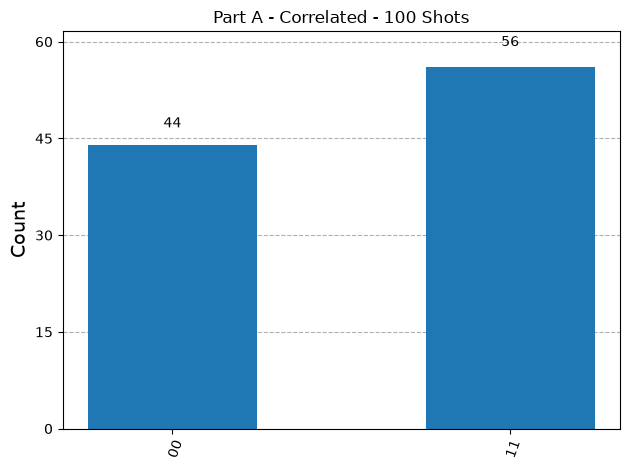

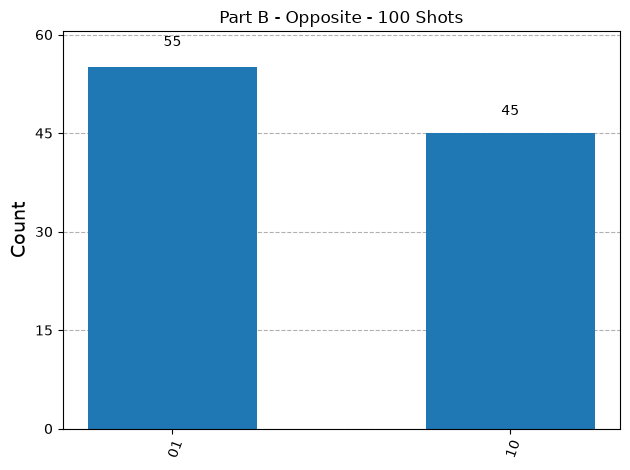

In [6]:
for name, counts in results.items():

    display(
        plot_histogram(
            counts,
            title=f"{name} - 100 Shots",
            bar_labels=True
        )
    )

In [7]:
print("PREDICTION VS ACTUAL RESULTS")
print("=" * 80)

print(
    f"{'Circuit':<25}"
    f"{'State':<10}"
    f"{'Predicted':<15}"
    f"{'Actual':<15}"
)

print("-" * 80)

for name in circuits:

    for state in ["00", "01", "10", "11"]:

        predicted = predictions[name][state]
        actual = results[name].get(state, 0)

        print(
            f"{name:<25}"
            f"{state:<10}"
            f"{predicted:<15}"
            f"{actual:<15}"
        )

    print("-" * 80)

PREDICTION VS ACTUAL RESULTS
Circuit                  State     Predicted      Actual         
--------------------------------------------------------------------------------
Part A - Correlated      00        50             44             
Part A - Correlated      01        0              0              
Part A - Correlated      10        0              0              
Part A - Correlated      11        50             56             
--------------------------------------------------------------------------------
Part B - Opposite        00        0              0              
Part B - Opposite        01        50             55             
Part B - Opposite        10        50             45             
Part B - Opposite        11        0              0              
--------------------------------------------------------------------------------


In [8]:
print("QUANTUM CORRELATION SWITCH ANALYSIS")
print("=" * 60)

for name, counts in results.items():

    same = counts.get("00", 0) + counts.get("11", 0)
    opposite = counts.get("01", 0) + counts.get("10", 0)

    correlation = (same - opposite) / shots

    print(f"\n{name}")
    print(f"Same outcomes     : {same}")
    print(f"Opposite outcomes : {opposite}")
    print(f"Correlation value : {correlation:.2f}")

    if correlation == 1:
        print("Perfect positive correlation")
    elif correlation == -1:
        print("Perfect negative correlation")
    else:
        print("Partial correlation")

QUANTUM CORRELATION SWITCH ANALYSIS

Part A - Correlated
Same outcomes     : 100
Opposite outcomes : 0
Correlation value : 1.00
Perfect positive correlation

Part B - Opposite
Same outcomes     : 0
Opposite outcomes : 100
Correlation value : -1.00
Perfect negative correlation


In [9]:
print("CHALLENGE 4 VALIDATION")
print("=" * 60)

for name, circuit in circuits.items():

    assert circuit.num_qubits == 2
    assert circuit.num_clbits == 2

    operations = circuit.count_ops()

    assert operations.get("measure", 0) == 2

    gate_count = sum(
        count for gate, count in operations.items()
        if gate != "measure"
    )

    assert gate_count <= 4
    assert sum(results[name].values()) == 100

    print(f"PASS: {name}")

# Verify correlation behavior
assert results["Part A - Correlated"].get("01", 0) == 0
assert results["Part A - Correlated"].get("10", 0) == 0

assert results["Part B - Opposite"].get("00", 0) == 0
assert results["Part B - Opposite"].get("11", 0) == 0

# Verify gate modification
assert circuit_a.count_ops().get("h", 0) == 1
assert circuit_a.count_ops().get("cx", 0) == 1

assert circuit_b.count_ops().get("h", 0) == 1
assert circuit_b.count_ops().get("cx", 0) == 1
assert circuit_b.count_ops().get("x", 0) == 1

print("\nPASS: Correlation switch verified.")
print("PASS: All challenge constraints satisfied.")

CHALLENGE 4 VALIDATION
PASS: Part A - Correlated
PASS: Part B - Opposite

PASS: Correlation switch verified.
PASS: All challenge constraints satisfied.


## Challenge 4 — Results and Conclusion

The Quantum Correlation Switch experiment demonstrates how a single quantum gate can change the measurement relationship between two entangled qubits.

Part A — Correlated Outcomes: A Hadamard gate followed by a CNOT gate prepares the Bell state \((|00\rangle+|11\rangle)/\sqrt{2}\). This produces matching measurement outcomes, either 00 or 11, with approximately equal probabilities.

Part B — Opposite Outcomes: An additional X gate applied to the second qubit transforms the state into \((|01\rangle+|10\rangle)/\sqrt{2}\). This produces opposite measurement outcomes, either 01 or 10.

Both circuits are executed using 100 shots. The experiment demonstrates that applying a local X gate switches the measurement correlation from positive to negative while preserving quantum entanglement.

Conclusion: Quantum correlations can be controlled using simple quantum gates. The experiment successfully demonstrates a switch between correlated and anti-correlated measurement outcomes without increasing the circuit complexity beyond the workshop constraints.